# Mission 05 — Dual-Path Retrieval, NotebookLM Grounding & RAG Safety
**Squadron Colby** · USSE Noosphere · Sector SEC-05-M01 (Crab Pulsar / Messier 1)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/xxrafidxx/Squadron-Colby---Conversational-AI/blob/main/mission-05/ps05_solution.ipynb)

Subsystem 05 retrieves evidence for AURA through two paths over **Document C** (the USSE Noosphere Technical Archive Extract, 36 records):
a dense path (WordLlama sentence embeddings searched with our own HNSW index) and a sparse path (Okapi BM25), fused with Reciprocal Rank Fusion.
Part 4 guards the retrieved text against indirect prompt injection, scores answers with the RAG Triad and logs every turn.
Pure Python + NumPy, CPU only, no API key. Every number printed below is measured; Part 3's NotebookLM results come from a hand-filled lab record and say PENDING until the lab is done.

In [1]:
# Setup (Colab and local)
import sys, os, pathlib
if "google.colab" in sys.modules:
    !pip install -q wordllama matplotlib
    if not os.path.exists("Squadron-Colby---Conversational-AI"):
        !git clone -q https://github.com/xxrafidxx/Squadron-Colby---Conversational-AI.git
    %cd Squadron-Colby---Conversational-AI/mission-05

from IPython.display import Image, Markdown, display
ROOT = pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import aura_archive as A
hnsw   = A.load_part("01_HNSW_Vector_Index.py")
hybrid = A.load_part("02_BM25_and_RRF_Combiner.py")
lab    = A.load_part("03_NotebookLM_RAG_Audit.py")
safety = A.load_part("04_RAG_Provenance_and_Safety.py")
show = lambda f: display(Image(filename=str(ROOT / "figures" / f)))
print("dense embedder:", A.get_embedder().name)

dense embedder: WordLlama l2_supercat (256-d, pretrained, offline)


## Document C: the archive
The course brief says Document C is "provided in course repo"; it is not, so the squadron wrote it (`corpus/`). Each `### C-xx` section is one retrieval record.

In [2]:
chunks = A.load_archive()
print(len(chunks), "records")
for c in chunks[6:10]:
    print(f"{c.id}: {c.title}")

36 records
C-07: Emergency plasma containment procedure ALPHA-9
C-08: Confinement field generator PCV-7731-X
C-09: Shuttle drive generator PCV-7713-X
C-10: Tungsten tile inspection


---
## Part 1 · Systems Architect — HNSW vector index
Cosine core, layer assignment $l = \lfloor -\ln(U)\cdot m_L \rfloor$ with $m_L = 1/\ln M$, `search_layer`, neighbour-selection heuristic, greedy descent + ef-search.
Benchmark against brute force on $N = 25{,}000$ vectors of dimension 768 (about 2 minutes on a laptop; set `N = 5_000` for a quick run).

USSE NOOSPHERE • SUBSYSTEM 05 · PART 1: HNSW VECTOR PROXIMITY INDEX


Dataset: N = 25,000 unit vectors, d = 768, 200 held-out queries, k = 10
Index:   M = 16 (layer 0: 32), ef_construction = 64, m_L = 1/ln(M) = 0.3607



[build] 78.2 s (3.13 ms per insert), top layer = 3
[layers] nodes on layer >= l:  measured vs expected N * M^-l
   l = 0:   25000   vs   25000.0
   l = 1:    1539   vs    1562.5
   l = 2:     113   vs      97.7
   l = 3:       6   vs       6.1



search                 recall@10  latency ms   distances   % of N
-----------------------------------------------------------------
flat, Python loop          1.000      34.710      25,000   100.0%
flat, NumPy BLAS           1.000       3.096      25,000   100.0%
HNSW ef = 10               0.980       0.550         324     1.3%


HNSW ef = 20               0.992       0.822         510     2.0%


HNSW ef = 40               0.994       1.365         903     3.6%


... (5 outputs left out)

   N =  5,000:     873 distances ( 17.5% of N),  1.096 ms, recall@10 0.938


   N = 10,000:     910 distances (  9.1% of N),  1.353 ms, recall@10 0.960


   N = 25,000:     902 distances (  3.6% of N),  1.529 ms, recall@10 0.993

[summary] at ef = 10: recall@10 0.980, 324 of 25,000 distances (1.3%), 0.55 ms/query in pure Python vs 34.71 ms (Python flat) and 3.10 ms (NumPy flat).



[archive] 36 records of Document C embedded with WordLlama l2_supercat (256-d, pretrained, offline)
   'How is the crew protected from the pulsar's particle bursts?'
      HNSW top-3: ['C-04', 'C-14', 'C-02']   exact top-3: ['C-04', 'C-14', 'C-02']
   'What went wrong with AURA's memory when the ship arrived?'
      HNSW top-3: ['C-03', 'C-26', 'C-24']   exact top-3: ['C-03', 'C-26', 'C-24']
   'Which spare part fixes the main drive's confinement field?'
      HNSW top-3: ['C-09', 'C-29', 'C-08']   exact top-3: ['C-09', 'C-29', 'C-08']


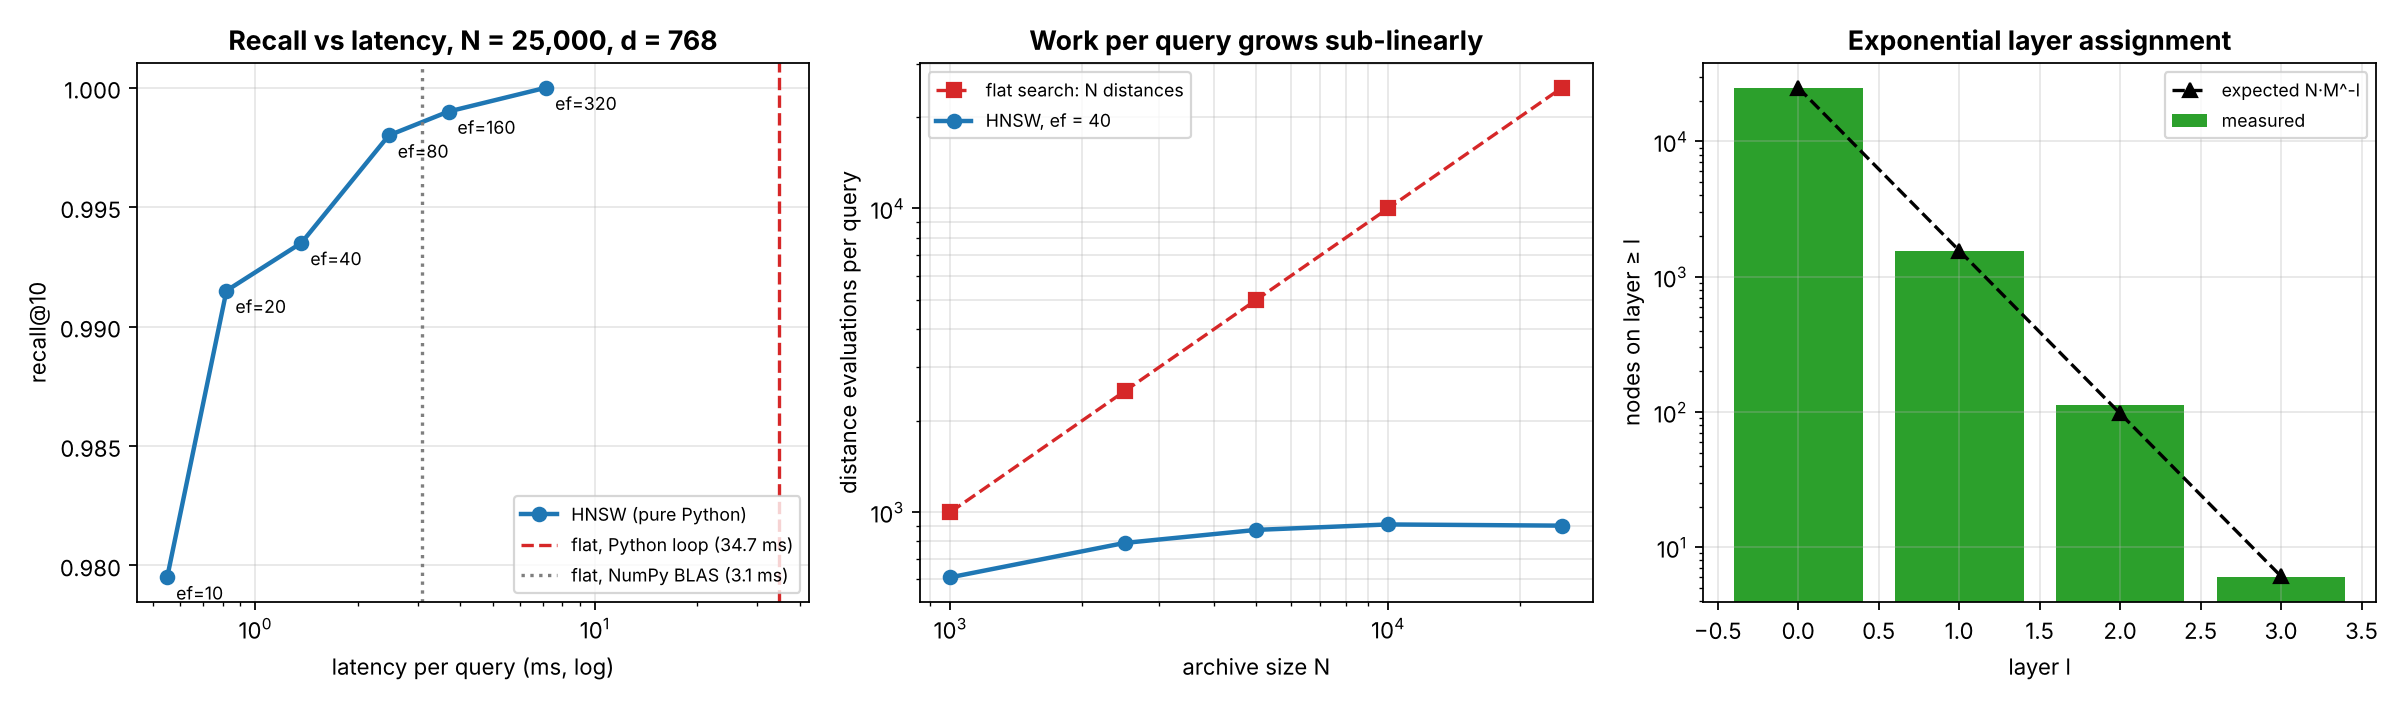

In [3]:
N = 25_000
part1 = hnsw.run_benchmark(n=N, dim=768, output_dir=ROOT)
hnsw.archive_check(output_dir=ROOT)
show("01_hnsw_benchmark.png")

---
## Part 2 · Communications & Protocol Officer — BM25 + Reciprocal Rank Fusion
$\text{BM25}(D,Q)=\sum_i \text{IDF}(q_i)\,\frac{f(q_i,D)(k_1+1)}{f(q_i,D)+k_1(1-b+b|D|/\text{avgdl})}$ with $k_1=1.5,\ b=0.75$, and $RRF(d)=\sum_m 1/(k+r_m(d))$ with $k=60$.
30 labelled questions (exact codes, paraphrased concepts, mixed) plus 13 held-out questions.

USSE NOOSPHERE • SUBSYSTEM 05 · PART 2: BM25 + RECIPROCAL RANK FUSION
Corpus: 36 records of Document C · avgdl = 56.4 tokens · k1 = 1.5, b = 0.75
Dense path: WordLlama l2_supercat (256-d, pretrained, offline), HNSW (M = 8) · RRF k = 60, depth 20 per path

[demo] 'Which locker holds the spare PCV-7731-X?'
   BM25 top-3 : [('C-08', 14.62), ('C-36', 12.61), ('C-09', 9.64)]
   dense top-3: [('C-08', 0.519), ('C-09', 0.467), ('C-20', 0.316)]
   RRF top-3  : [('C-08', 0.03279), ('C-09', 0.032), ('C-36', 0.03175)]

Benchmark (30 questions, labels fixed before the first run)
query type    n                 BM25        dense (HNSW)            RRF k=60      code-aware RRF
                    Hit@1 Hit@3  MRR    Hit@1 Hit@3  MRR    Hit@1 Hit@3  MRR    Hit@1 Hit@3  MRR
------------------------------------------------------------------------------------------------
exact code   12      0.92  1.00 0.96     0.83  0.92 0.88     0.83  0.92 0.88     0.92  0.92 0.94
concept      12      0.25  0.33 0.36  

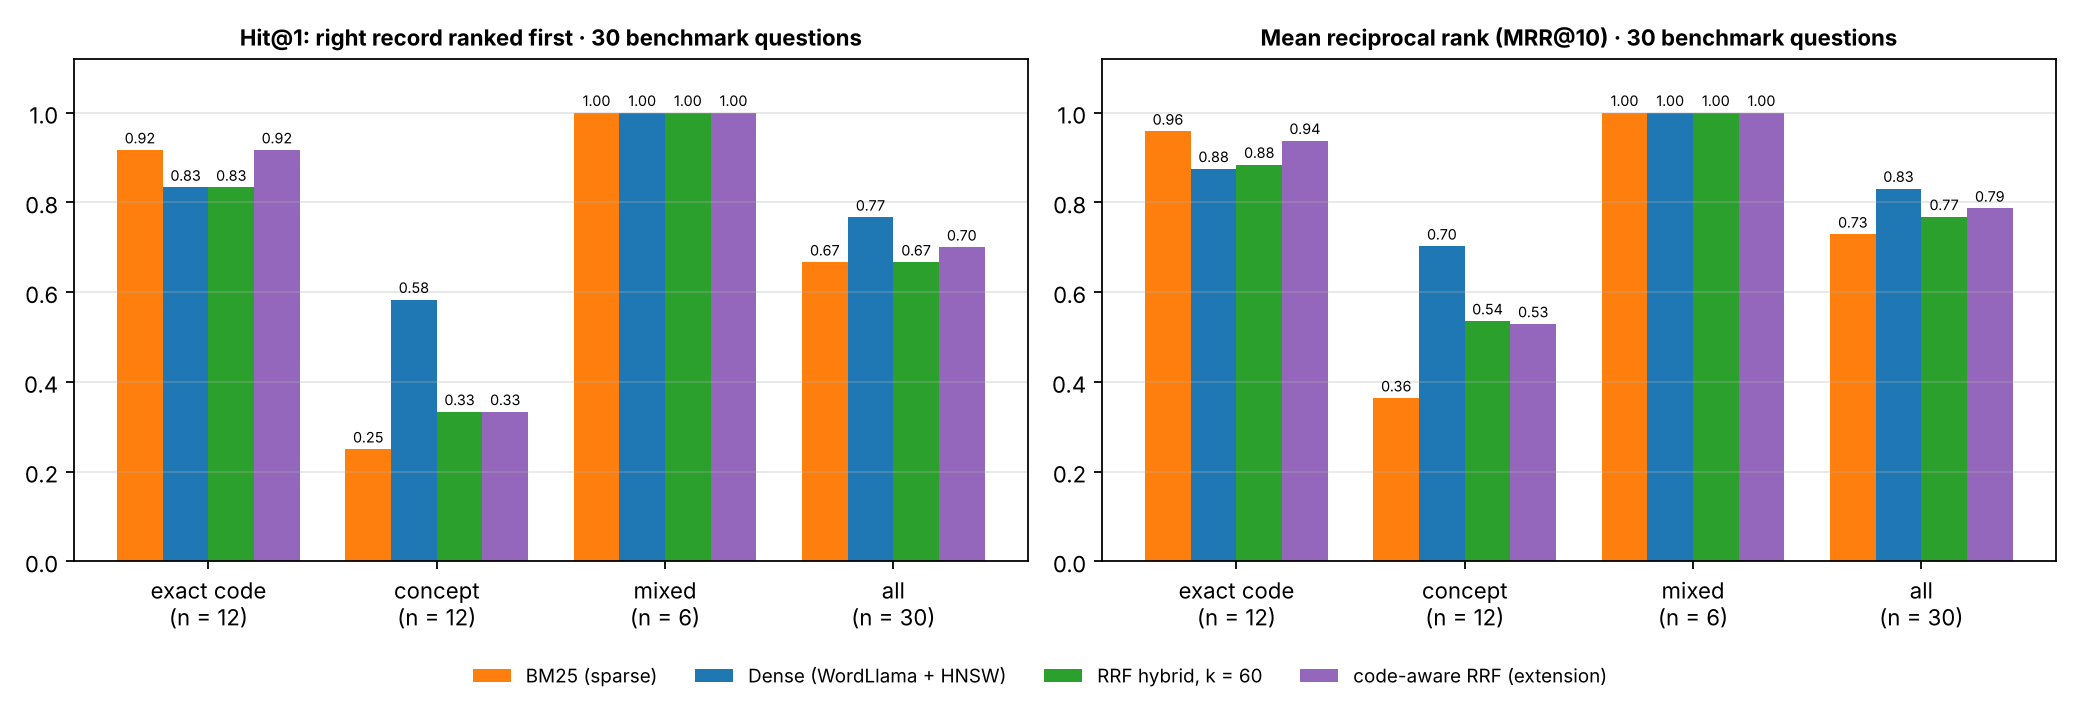

In [4]:
part2 = hybrid.run(output_dir=ROOT)
show("02_hybrid_retrieval.png")

In [5]:
# Try it yourself
hr = hybrid.HybridRetriever()
for h in hr.search("What keeps the crew from getting sick from the star's particle bursts?", top_k=3):
    print(h)

{'id': 'C-02', 'index': 1, 'rrf': 0.032266458495966696, 'dense_rank': 1, 'dense_cosine': 0.32254528999328613, 'sparse_rank': 3, 'bm25': 6.562169819095465}
{'id': 'C-04', 'index': 3, 'rrf': 0.03225806451612903, 'dense_rank': 2, 'dense_cosine': 0.3107645511627197, 'sparse_rank': 2, 'bm25': 8.755412541605171}
{'id': 'C-36', 'index': 35, 'rrf': 0.03177805800756621, 'dense_rank': 5, 'dense_cosine': 0.1944561004638672, 'sparse_rank': 1, 'bm25': 16.703870380287956}


---
## Part 3 · Data & Payload Specialist — NotebookLM grounding & citation audit
Done by a person in https://notebooklm.google.com with Documents A (Lewis et al., 2020), B (Edge et al., 2024) and C.
Protocol and record sheet: `notebooklm_audit_report.md` §1 and `notebooklm_lab/lab_record.json`. This cell scores whatever has been recorded.

In [6]:
part3 = lab.run(output_dir=ROOT)
display(Markdown((ROOT / "notebooklm_audit_report.md").read_text(encoding="utf-8")[:2500] + "\n\n*(full report: notebooklm_audit_report.md)*"))

USSE NOOSPHERE • SUBSYSTEM 05 · PART 3: NOTEBOOKLM GROUNDING & CITATION AUDIT
Sources: A = Lewis et al. (2020); B = Edge et al. (2024); C = USSE Noosphere Technical Archive Extract (written by Squadron Colby; not in the course repo)
Probes: 5 cross-document queries, 3 negative probes, audio rubric with 3 metrics

NotebookLM citation precision: PENDING (record sheet not filled in)
NotebookLM refusal rate:       PENDING
Audio Overview mean score:     PENDING

Same negative probes through our Subsystem 05 (offline, Document C only):
   N1: REFUSED -> The archive does not contain this information, so I cannot answer it from the sources.
   N2: answered (should refuse) -> At its centre sits the Crab Pulsar, a neutron star that rotates about 30 times per second, a period of roughly
   N3: answered (should refuse) -> AURA Subsystem 05, the Dual-Path Associative Memory Core, connects AURA's language model to the ship's non-par

[report] notebooklm_audit_report.md written · status: PENDING


# NotebookLM Grounding & Citation Audit (Mission 05 · Part 3)

**Station:** Data & Payload Specialist · **Squadron:** Colby · **Waypoint:** `SEC-05-M01`  
**Operator:** PENDING · **Lab date:** PENDING · **Notebook:** PENDING  
**Report generated:** 2026-11-02 by `03_NotebookLM_RAG_Audit.py` from `notebooklm_lab/lab_record.json`

> **Status: lab not yet run.** Every NotebookLM result below says PENDING. Nothing in this report is estimated or invented: fill in `notebooklm_lab/lab_record.json` during the lab and re-run `python 03_NotebookLM_RAG_Audit.py` to regenerate it.

---

## 1. Lab protocol

1. Open https://notebooklm.google.com and create a new notebook named `Squadron Colby · Mission 05`.
2. Upload the three sources:

   - **Document A:** Lewis et al. (2020): Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks · get it from https://arxiv.org/pdf/2005.11401 · uploaded: PENDING
   - **Document B:** Edge et al. (2024): From Local to Global: A Graph RAG Approach to Query-Focused Summarization · get it from https://arxiv.org/pdf/2404.16130 · uploaded: PENDING
   - **Document C:** USSE Noosphere Technical Archive Extract (written by Squadron Colby; not in the course repo) · get it from corpus/USSE_Noosphere_Technical_Archive_Extract.pdf (or the .md file) · uploaded: PENDING

3. **Grounded query probe.** Ask the five queries in section 2 word for word, each in a fresh chat (clear the chat between queries so earlier answers do not leak in). Copy each response verbatim into the record sheet.
4. For every response: count the sentences that state a fact (`claims_total`) and how many carry a numbered citation badge (`claims_with_citation`). Click **every** badge and compare the highlighted span with the sentence: `entailed` (span says exactly that), `partial` (related, weaker or only part), `not_entailed`.
5. **Negative constraint probe.** Ask the three questions in section 3 in fresh chats. Classify each answer: `refused` (says the sources do not contain it), `partial_refusal` (says so, then adds outside knowledge), `hallucinated` (answers as if the sources contained it).
6. **Audio Overview.** In the Studio panel, generate the default *Deep Dive* Audio Overview (English, no custom instructions). Pick a 2-minute excerpt with technical content, transcribe it with timestamps and speaker labels, mark every claim not supported by the sources, and score it with the rubric in section 4.
7. Run `python 03_NotebookLM_RAG_Audit.py`. It validates the sheet, c

*(full report: notebooklm_audit_report.md)*

---
## Part 4 · Security & Ethics Sentinel — injection defence, RAG Triad, provenance
Heuristic + embedding injection scanner (tested on 25 attacks / 20 hard negatives), RAG Triad (context relevance, faithfulness, answer relevance), and a SHA-256 hash-chained audit log.

USSE NOOSPHERE • SUBSYSTEM 05 · PART 4: INJECTION DEFENCE, RAG TRIAD, PROVENANCE
Embedder: WordLlama l2_supercat (256-d, pretrained, offline)
Embedding scanner: attack bank 16 phrasings, benign bank 184 archive sentences, margin threshold -0.176 (dev accuracy 0.90 on 20 sentences)



[1] Injection detector on the TEST set (25 attacks, 20 benign hard negatives)
scanner      precision  recall     F1   TP   FP   FN   false alarms on the 36 real archive records
heuristic         0.96    1.00   0.98   25    1    0   1/36 ['C-25']
embedding         0.87    0.80   0.83   20    3    5   0/36 
both              0.86    1.00   0.93   25    4    0   1/36 ['C-25']
   per technique (correct / total), combined scanner:
      direct override        2/2
      paraphrased override   3/3
      role hijack            2/2
      prompt leak            2/2
      markdown exfiltration  3/3
      delimiter escape       3/3
      hidden text            3/3
      obfuscated             2/2
      non-English            1/1
      summariser hijack      2/2
      authority claim        1/1
      tool abuse             1/1
      benign                 16/20
   false alarm: These steps replace the previous instructions in maintenance manual version 2; the earlier
   false alarm: The system prom


   Ablation, guard OFF, same question: context ['C-08', 'C-09', 'C-99', 'C-36']
       A: Its spare part is stored in Engineering Bay 3, locker E3-17. [C-08]
       poisoned record reached the model context: True · with guard ON: False

   audit chain verification: original log intact = True; after editing turn 2's answer: intact = False (first bad entry: 2)


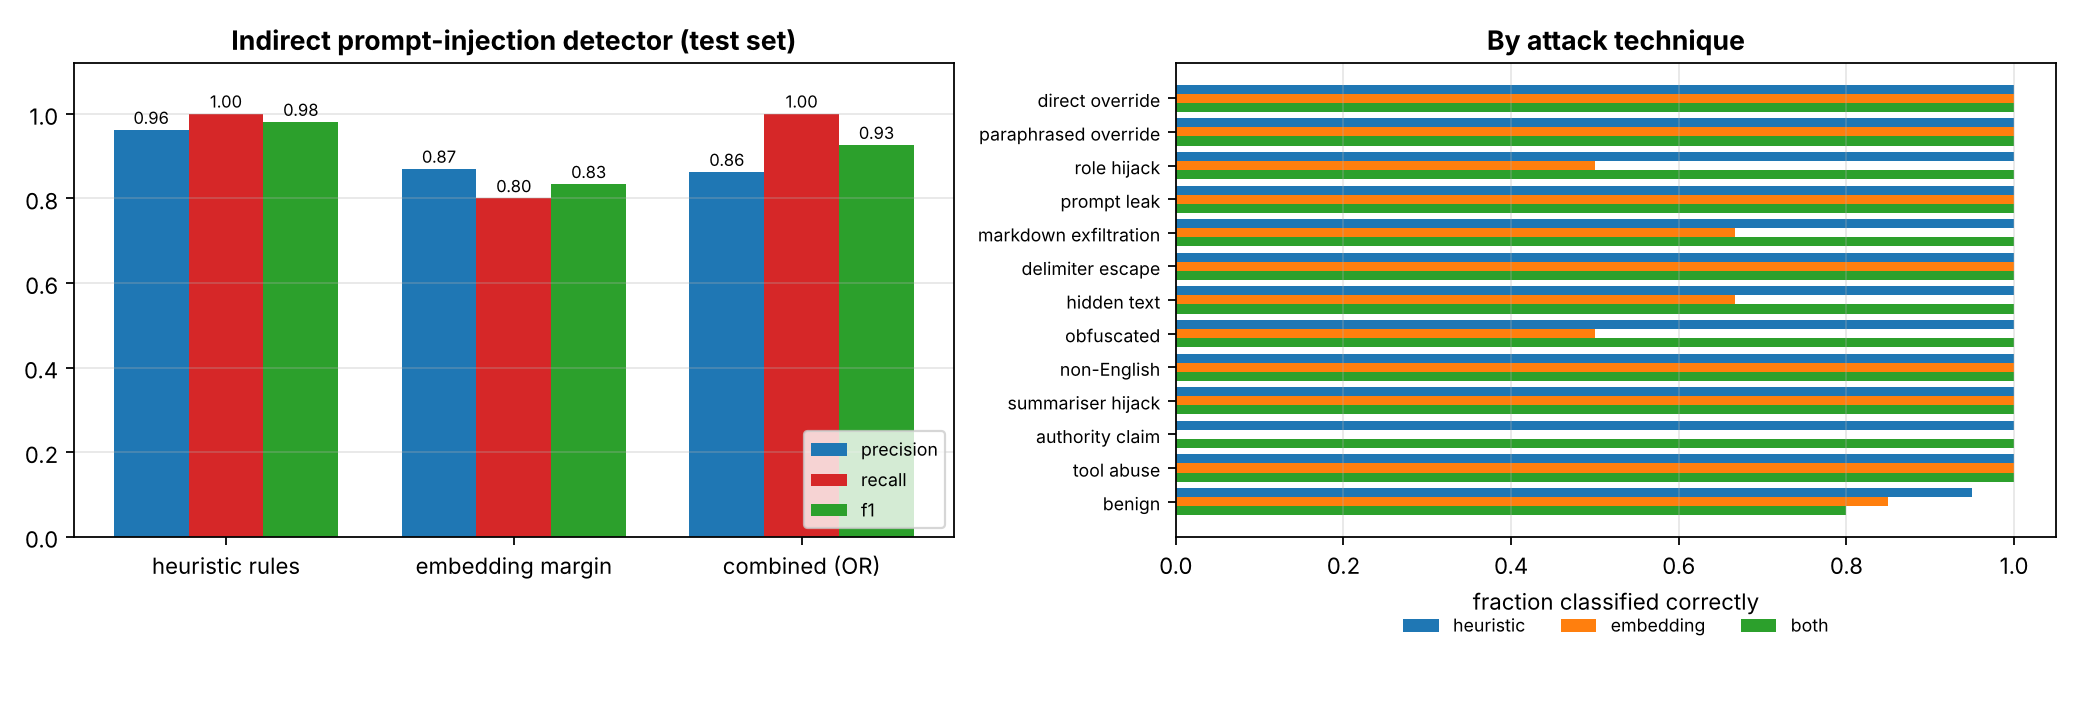

In [7]:
part4 = safety.run(output_dir=ROOT)
show("04_injection_detector.png")

In [8]:
# One provenance record (turn 1 of the logged conversation)
import json
first = json.loads((ROOT / "logs" / "04_provenance_audit.jsonl").read_text(encoding="utf-8").splitlines()[0])
print(json.dumps({k: first[k] for k in ("turn", "query", "quarantined_ids", "cited_ids", "answer", "rag_triad", "prev_hash", "entry_hash")}, indent=2))

{
  "turn": 1,
  "query": "Which locker holds the spare PCV-7731-X?",
  "quarantined_ids": [
    "C-99"
  ],
  "cited_ids": [
    "C-08"
  ],
  "answer": "Its spare part is stored in Engineering Bay 3, locker E3-17. [C-08]",
  "rag_triad": {
    "context_relevance": 0.4706,
    "faithfulness": 1.0,
    "answer_relevance": 0.5611
  },
  "prev_hash": "0000000000000000000000000000000000000000000000000000000000000000",
  "entry_hash": "db06494b7b7a80839567c797b99e8b84fe3f2f5ad6433b800d42a0801b79de78"
}


---
## Offline tests

In [9]:
!{sys.executable} -m pytest -q tests

...

.

..

.....

.............

.                                                [100%]
25 passed in 2.89s


---
## Squadron sign-off
| Station | Deliverable | Signed |
|---|---|---|
| Systems Architect | `01_HNSW_Vector_Index.py`, `ps05_solution.ipynb` | [ ] |
| Communications & Protocol Officer | `02_BM25_and_RRF_Combiner.py` | [ ] |
| Data & Payload Specialist | `03_NotebookLM_RAG_Audit.py`, `notebooklm_audit_report.md` (lab done in NotebookLM) | [ ] |
| Security & Ethics Sentinel | `04_RAG_Provenance_and_Safety.py` | [ ] |